# Using GEOparse Python Package - Microglia Data in GEO

In [164]:
!pip install GEOparse odfpy anndata scanpy pooch igraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 7.8 MB/s eta 0:00:00eta 0:00:01


In [101]:
from __future__ import annotations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import GEOparse
import requests
import gzip
import io
import anndata as ad
import pooch
import scanpy as sc

## Create dictionary of compiled GSEs from research

In [4]:
gse_dict = {
            "Transcriptomic profiling of microglia and astrocytes throughout aging": 137028,
            "Time-dependent changes in microglia transcriptional networks following traumatic brain injury": 132809,
            "Temporal tracking of microglia activation in neurodegeneration at single-cell resolution": 103334,
            "Transcriptional profiling of microglia; current state of the art and future perspectives": 135618,
            "Microglial reactivity and neuroinflammation-driven in motivational behaviors are regulated by Orai1 channels": 310141
           }

## GSE 132809 

### Experimental Design Clarification for above CCI Microglia NanoString Dataset
**Study Structure based on the Methods and Results sections**:
- Model: Controlled cortical impact (CCI)
- Subjects: 2-month-old male C57BL/6J mice

**Groups**:
- Sham (n = 4), 2 dpi (n = 4), 14 dpi (n = 4), 60 dpi (n = 3)

**Microglia were**:
- Isolated from brain tissue via enzymatic digestion
- Stained for CD11b and CD45
- Sorted using FACS
- RNA extracted and analyzed using NanoString nCounter (550 inflammation/immunity genes)

In [5]:
gse_132809 = GEOparse.get_GEO(geo="GSE132809", destdir="./")

09-Mar-2026 01:55:14 DEBUG utils - Directory ./ already exists. Skipping.
09-Mar-2026 01:55:14 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE132nnn/GSE132809/soft/GSE132809_family.soft.gz to ./GSE132809_family.soft.gz
100%|██████████| 56.7k/56.7k [00:00<00:00, 139kB/s] 
09-Mar-2026 01:55:16 DEBUG downloader - Size validation passed
09-Mar-2026 01:55:16 DEBUG downloader - Moving /tmp/tmpjv5q7wwe to /home/jovyan/Microglia-ML-Project/GEOparse/GSE132809_family.soft.gz
09-Mar-2026 01:55:16 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE132nnn/GSE132809/soft/GSE132809_family.soft.gz
09-Mar-2026 01:55:16 INFO GEOparse - Parsing ./GSE132809_family.soft.gz: 
09-Mar-2026 01:55:16 DEBUG GEOparse - DATABASE: GeoMiame
09-Mar-2026 01:55:16 DEBUG GEOparse - SERIES: GSE132809
09-Mar-2026 01:55:16 DEBUG GEOparse - PLATFORM: GPL26788
09-Mar-2026 01:55:16 DEBUG GEOparse - SAMPLE: GSM3892735
09-Mar-2026 01:55:16 DEBUG GEOparse - SAMPLE: GSM389273

In [6]:
for i, (gpl_name, gpl) in enumerate(gse_132809.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL26788
Metadata:
 - title : NanoString nCounter® Mouse Inflammation v2 Panel
 - geo_accession : GPL26788
 - status : Public on Jun 18 2019
 - submission_date : Jun 17 2019
 - last_update_date : Jun 18 2019
 - technology : other
 - distribution : custom-commercial
 - organism : Mus musculus
 - taxid : 10090
 - manufacturer : Nanostring
 - manufacture_protocol : see manufacturer's website
 - contact_name : Michael,,Whalen
 - contact_email : mwhalen@mgh.harvard.edu
 - contact_phone : 617-643-3933
 - contact_laboratory : Acute Brain Injury Research Laboratory
 - contact_department : Department of Pediatrics
 - contact_institute : Massachusetts General Hospital
 - contact_address : 149 13th Street Room 6303
 - contact_city : Charlestown
 - contact_state : MA
 - contact_zip/postal_code : 02129
 - contact_country : USA
 - data_row_count : 547
Table data:
            ID  Code.Class Gene.Name       GB_ACC
0  NM_019552.2  Endogenous    Abcb10  NM_019552.2
1  NM_011076.1  Endogenous    A

In [7]:
for i, (gsm_name, gsm) in enumerate(gse_132809.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break
    

Name:  GSM3892735
Metadata:
 - title : 20141015_cci_01_01.RCC
 - geo_accession : GSM3892735
 - status : Public on Jun 18 2019
 - submission_date : Jun 17 2019
 - last_update_date : Jun 18 2019
 - type : RNA
 - channel_count : 1
 - source_name_ch1 : brain
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : injury: sham
 - treatment_protocol_ch1 : NA
 - growth_protocol_ch1 : NA
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : Microglia isolated by FACS were stored in RNAlater Stabilization Solution (AM7020, Invitrogen) at -80°C until further processing. Total RNA from the sorted cells was extracted using miRNeasy Micro Kit from Qiagen (Redwood City, CA) for purification of total RNA from small amounts of cells according to the manufacturer's instructions. mRNA expression analysis with the NanoString nCounter® Mouse Inflammation v2 Panel was performed according to the manufacturer's protocol (NanoString Technologies Inc., Seattle, WA).
 - label_ch1 : N/A
 - l

## GSE 137028 

### Data Structure Clarification
This dataset is RNA-seq (“Expression profiling by high throughput sequencing”). Although GEO lists 60 samples, GEOparse does not return per-GSM SOFT expression tables because the processed data were not stored in individual GSM records.

**Instead**:
- Raw sequencing data are stored in SRA (BioProject PRJNA564299; SRP220678).
- The processed expression matrix is provided as a single supplementary file: `GSE137028_gene_fpkm.xls.gz`

**This file contains**:
- 35,999 genes
- 20 biological samples (columns)
- FPKM-normalized expression values

The 60 samples listed in GEO likely correspond to raw sequencing runs or technical libraries, which were aggregated into 20 condition-level profiles in the processed matrix.

**Factorial Column names**:
- Genotype: WT vs AD
- Age: 2m, 4m, 6m, 9m, 12m
- Group (likely sex): M and A

So there are **2×5×2=20 processed samples**

Thus, GEOparse shows no GSM tables because the usable expression data are stored in the supplementary file rather than in SOFT-formatted per-sample tables.

In [8]:
gse_137028 = GEOparse.get_GEO(geo="GSE137028", destdir="./")

09-Mar-2026 01:55:31 DEBUG utils - Directory ./ already exists. Skipping.
09-Mar-2026 01:55:31 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/soft/GSE137028_family.soft.gz to ./GSE137028_family.soft.gz
100%|██████████| 5.77k/5.77k [00:00<00:00, 18.1kB/s]
09-Mar-2026 01:55:32 DEBUG downloader - Size validation passed
09-Mar-2026 01:55:32 DEBUG downloader - Moving /tmp/tmpbv9rc90y to /home/jovyan/Microglia-ML-Project/GEOparse/GSE137028_family.soft.gz
09-Mar-2026 01:55:32 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/soft/GSE137028_family.soft.gz
09-Mar-2026 01:55:32 INFO GEOparse - Parsing ./GSE137028_family.soft.gz: 
09-Mar-2026 01:55:32 DEBUG GEOparse - DATABASE: GeoMiame
09-Mar-2026 01:55:32 DEBUG GEOparse - SERIES: GSE137028
09-Mar-2026 01:55:32 DEBUG GEOparse - PLATFORM: GPL24247
09-Mar-2026 01:55:32 DEBUG GEOparse - SAMPLE: GSM4065891
09-Mar-2026 01:55:32 DEBUG GEOparse - SAMPLE: GSM406589

In [12]:
for i, (gpl_name, gpl) in enumerate(gse_137028.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL24247
Metadata:
 - title : Illumina NovaSeq 6000 (Mus musculus)
 - geo_accession : GPL24247
 - status : Public on Nov 08 2017
 - submission_date : Nov 08 2017
 - last_update_date : Mar 08 2019
 - technology : high-throughput sequencing
 - distribution : virtual
 - organism : Mus musculus
 - taxid : 10090
 - contact_name : ,,GEO
 - contact_country : USA
 - data_row_count : 0
Table data:
Empty DataFrame
Columns: []
Index: []


In [13]:
for i, (gsm_name, gsm) in enumerate(gse_137028.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break
    

Name:  GSM4065891
Metadata:
 - title : WT2m1M
 - geo_accession : GSM4065891
 - status : Public on Apr 17 2020
 - submission_date : Sep 06 2019
 - last_update_date : Apr 17 2020
 - type : SRA
 - channel_count : 1
 - source_name_ch1 : Brain
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : strain: C57BL/6, age: 2-month-old
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : RNA was isolated from flow cytometry-sorted cell populations using RNeasy Micro Kit (74004, Qiagen), A total amount of 10 ng RNA per sample was used as input material for the RNA sample preparations. Libraries were generated using SMART-Seq v4 Ultra Low Input RNA Kit (634892, Takara Bio USA, Mountain View, CA, USA) following manufacturer’s recommendations and index codes were added to attribute sequences to each sample. Briefly, first-strand cDNA synthesis from total RNA is primed by the 3’ SMART-Seq CDS Primer II A and uses the SMART-Seq v4 Oligonucleotide for template switching at the 5’

In [11]:
print(gse_137028.metadata.get("type", []))
print(gse_137028.metadata.get("supplementary_file", [])[:10])
print(gse_137028.relations)

['Expression profiling by high throughput sequencing']
['ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/suppl/GSE137028_gene_fpkm.xls.gz']
{'BioProject': ['https://www.ncbi.nlm.nih.gov/bioproject/PRJNA564299'], 'SRA': ['https://www.ncbi.nlm.nih.gov/sra?term=SRP220678']}


In [14]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/suppl/GSE137028_gene_fpkm.xls.gz"
r = requests.get(url)
compressed_file = io.BytesIO(r.content)
with gzip.open(compressed_file) as f:
    df_137028 = pd.read_excel(f)

print(df_137028.head())
print(df_137028.shape)

              gene_id         WT2mM         WT4mM         WT6mM         WT9mM  \
0  ENSMUSG00000027447  68165.002270  77992.193419  66575.831713  43885.059333   
1  ENSMUSG00000024661   3845.103176   3692.195390   4967.818359   4061.208478   
2  ENSMUSG00000038642  12817.844190  13731.290151  19752.756756  11134.137593   
3  ENSMUSG00000049775  10578.664606  10245.166862  12059.352638   8408.865137   
4  ENSMUSG00000036905  10487.262630  11009.635127  13231.701913   7128.882128   

         WT12mM         AD2mM         AD4mM         AD6mM         AD9mM  ...  \
0  39332.275233  76493.920895  51811.192955  64800.386824  38448.689027  ...   
1   3834.502813   4023.522699   3927.298858   4896.643218   3907.164574  ...   
2   9986.886380  13577.022817  11830.694712  18414.985153   8232.700179  ...   
3   6129.744878  10192.700050   9137.571661  13293.544775   6169.016818  ...   
4   7616.056069  12719.295809  10962.208895  13423.054268   5844.781359  ...   

          WT2mA         WT4mA   

## MOVE AWAY FROM AGGREGATE VALUES FROM SAMPLES, NEED SINGLE CELL GENETIC EXPRESSION

## GSE 103334 (Single cell)

In [ ]:
gse_103334 = GEOparse.get_GEO(geo="GSE103334", destdir="./")

In [16]:
for i, (gpl_name, gpl) in enumerate(gse_103334.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL13112
Metadata:
 - title : Illumina HiSeq 2000 (Mus musculus)
 - geo_accession : GPL13112
 - status : Public on Feb 02 2011
 - submission_date : Feb 02 2011
 - last_update_date : Mar 19 2019
 - technology : high-throughput sequencing
 - distribution : virtual
 - organism : Mus musculus
 - taxid : 10090
 - contact_name : ,,GEO
 - contact_country : USA
 - data_row_count : 0
Table data:
Empty DataFrame
Columns: []
Index: []


In [18]:
for i, (gsm_name, gsm) in enumerate(gse_103334.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break


Name:  GSM2766573
Metadata:
 - title : RNA-Seq single cell_CK_2w_m2_A1
 - geo_accession : GSM2766573
 - status : Public on Oct 10 2017
 - submission_date : Aug 31 2017
 - last_update_date : May 15 2019
 - type : SRA
 - channel_count : 1
 - source_name_ch1 : CK_2w_m2
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : strain: CK, age: 3 months and 2 weeks, cell type: isolated, FACS sorted single hippocampal microglia
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : Hippocampal tissue was enzymatically digested using the Neural Tissue Dissociation Kit (P) (Miltenyi Biotec, catalogue number 130-092-628) according to the manufacturer’s protocol., FACS sorted single cell lysis in 96-well plates were subject to Smart-seq2 RNA library preparation. A QC step was performed to check amplification of the libraries before multiplexing for sequencing., RNA from single cells was first purified with Agencourt RNAClean XP beads (Beckman Coulter, catalogue number A63987) b

In [19]:
print(gse_103334.metadata.get("type", []))
print(gse_103334.metadata.get("supplementary_file", [])[:10])
print(gse_103334.relations)

['Expression profiling by high throughput sequencing']
['ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz']
{'BioProject': ['https://www.ncbi.nlm.nih.gov/bioproject/PRJNA401847']}


## Supplementary File Contains 2208 Single Cell Observations Across 4 Measurements with 23951 Genes being included.

### We can model data gaps, interpolating via polynomial fitting for some additional synthetic data?

In [37]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz"
r = requests.get(url)
compressed_file = io.BytesIO(r.content)
with gzip.open(compressed_file) as f:
    df_103334 = pd.read_csv(f, sep='\t')

print(df_103334.head())
print(df_103334.shape)

           GENES  CK_0w_m3_A1  CK_0w_m3_A10  CK_0w_m3_A11  CK_0w_m3_A12  \
0  0610005C13Rik     0.379103           0.0           0.0           0.0   
1  0610007P14Rik    11.727700           0.0           0.0           0.0   
2  0610009B22Rik    22.040700           0.0           0.0           0.0   
3  0610009L18Rik     4.056480           0.0           0.0           0.0   
4  0610009O20Rik    10.932400           0.0           0.0           0.0   

   CK_0w_m3_A2  CK_0w_m3_A3  CK_0w_m3_A4  CK_0w_m3_A5  CK_0w_m3_A6  ...  \
0          0.0          0.0          0.0          0.0          0.0  ...   
1          0.0          0.0          0.0          0.0          0.0  ...   
2          0.0          0.0          0.0          0.0          0.0  ...   
3          0.0          0.0          0.0          0.0          0.0  ...   
4          0.0          0.0          0.0          0.0          0.0  ...   

   CKp25_6w_m4_H11  CKp25_6w_m4_H12  CKp25_6w_m4_H2  CKp25_6w_m4_H3  \
0            0.000         

In [40]:
df_103334.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23951 entries, 0 to 23950
Columns: 2209 entries, GENES to CKp25_6w_m4_H9_0
dtypes: float64(2208), object(1)
memory usage: 403.7+ MB


In [41]:
df_103334.describe()

,CK_0w_m3_A1,CK_0w_m3_A10,CK_0w_m3_A11,CK_0w_m3_A12,CK_0w_m3_A2,CK_0w_m3_A3,CK_0w_m3_A4,CK_0w_m3_A5,CK_0w_m3_A6,CK_0w_m3_A7,...,CKp25_6w_m4_H11,CKp25_6w_m4_H12,CKp25_6w_m4_H2,CKp25_6w_m4_H3,CKp25_6w_m4_H4,CKp25_6w_m4_H5,CKp25_6w_m4_H6,CKp25_6w_m4_H7,CKp25_6w_m4_H8,CKp25_6w_m4_H9_0
count,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,...,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000
mean,15.872177,10.694415,17.333124,13.019686,18.213701,16.179573,17.770292,15.831723,12.108316,11.685200,...,20.090375,17.665154,16.744925,15.936848,18.467950,17.928028,13.351653,20.958837,18.672051,15.751943
std,395.454306,317.799722,397.824780,329.984935,361.918014,397.424481,477.475324,477.160555,267.703832,284.111374,...,454.096437,328.632632,490.759637,270.065156,453.281957,481.313742,318.298733,510.274608,456.118352,245.269284
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.180094,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.649805,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,56945.000000,37194.800000,46548.800000,29299.800000,31780.300000,41157.900000,60070.800000,58436.800000,25972.200000,32045.900000,...,54842.900000,22012.300000,60544.300000,26078.600000,60021.100000,61205.700000,35137.100000,58634.000000,61677.700000,27145.900000


In [48]:
df_103334.isna().sum().sum()

np.int64(0)

In [50]:
df_103334.columns

Index(['GENES', 'CK_0w_m3_A1', 'CK_0w_m3_A10', 'CK_0w_m3_A11', 'CK_0w_m3_A12',
       'CK_0w_m3_A2', 'CK_0w_m3_A3', 'CK_0w_m3_A4', 'CK_0w_m3_A5',
       'CK_0w_m3_A6',
       ...
       'CKp25_6w_m4_H11', 'CKp25_6w_m4_H12', 'CKp25_6w_m4_H2',
       'CKp25_6w_m4_H3', 'CKp25_6w_m4_H4', 'CKp25_6w_m4_H5', 'CKp25_6w_m4_H6',
       'CKp25_6w_m4_H7', 'CKp25_6w_m4_H8', 'CKp25_6w_m4_H9_0'],
      dtype='object', length=2209)

## Need to separate the dataframe by observation week, & transpose each so that n*p matrix is result and each included gene list as the column header

In [91]:
gene_list = df_103334.GENES.to_list()

In [93]:
df_103334_0w = df_103334.filter(regex=r'_0w_').T
df_103334_0w.columns = gene_list

In [94]:
df_103334_0w.shape

(576, 23951)

In [95]:
df_103334_1w = df_103334.filter(regex=r'_1w_').T
df_103334_1w.columns = gene_list

In [82]:
df_103334_1w.shape

(577, 23951)

In [96]:
df_103334_2w = df_103334.filter(regex=r'_2w_').T
df_103334_2w.columns = gene_list

In [84]:
df_103334_2w.shape

(577, 23951)

In [97]:
df_103334_6w = df_103334.filter(regex=r'_6w_').T
df_103334_6w.columns = gene_list

In [86]:
df_103334_6w.shape

(481, 23951)

## Take look at 0th week observations

In [98]:
df_103334_0w.head()

,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
CK_0w_m3_A1,0.379103,11.7277,22.0407,4.05648,10.9324,0.082063,5.23899,55.5093,8.48037,11.0711,...,0.0,1.71918,1.10084,1.44597,1.99025,0.0,4.16773,7.22038,4.6969,2.42857
CK_0w_m3_A10,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000
CK_0w_m3_A11,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,73.3392,0.00000,0.0000,...,0.0,0.00000,4.44716,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,12.34380
CK_0w_m3_A12,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,42.88510,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000
CK_0w_m3_A2,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000


## Configure ScanPy figure parameters, convert df into Annotated Data object with AnnData

In [124]:
sc.set_figure_params(dpi=100, facecolor="white")

In [105]:
adata_103334_0w = ad.AnnData(df_103334_0w)

In [111]:
adata_103334_0w

AnnData object with n_obs × n_vars = 576 × 23951

In [108]:
adata_103334_0w.X

array([[3.79103e-01, 1.17277e+01, 2.20407e+01, ..., 7.22038e+00,
        4.69690e+00, 2.42857e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 1.23438e+01],
       ...,
       [0.00000e+00, 0.00000e+00, 1.51743e+02, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 5.75027e+02, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00]])

## Calculate Quality Control Metrics from new matrix using Log1p transformation

In [113]:
sc.pp.calculate_qc_metrics(adata_103334_0w, inplace=True, log1p=True)

In [126]:
adata_103334_0w.obs.columns

Index(['n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts',
       'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes'],
      dtype='object')

In [128]:
adata_103334_0w.var.columns

Index(['n_cells_by_counts', 'mean_counts', 'log1p_mean_counts',
       'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'],
      dtype='object')

## Create plots of some QC metrics (can separate genes later if we want to have genetic cluster as well as observation cluster)

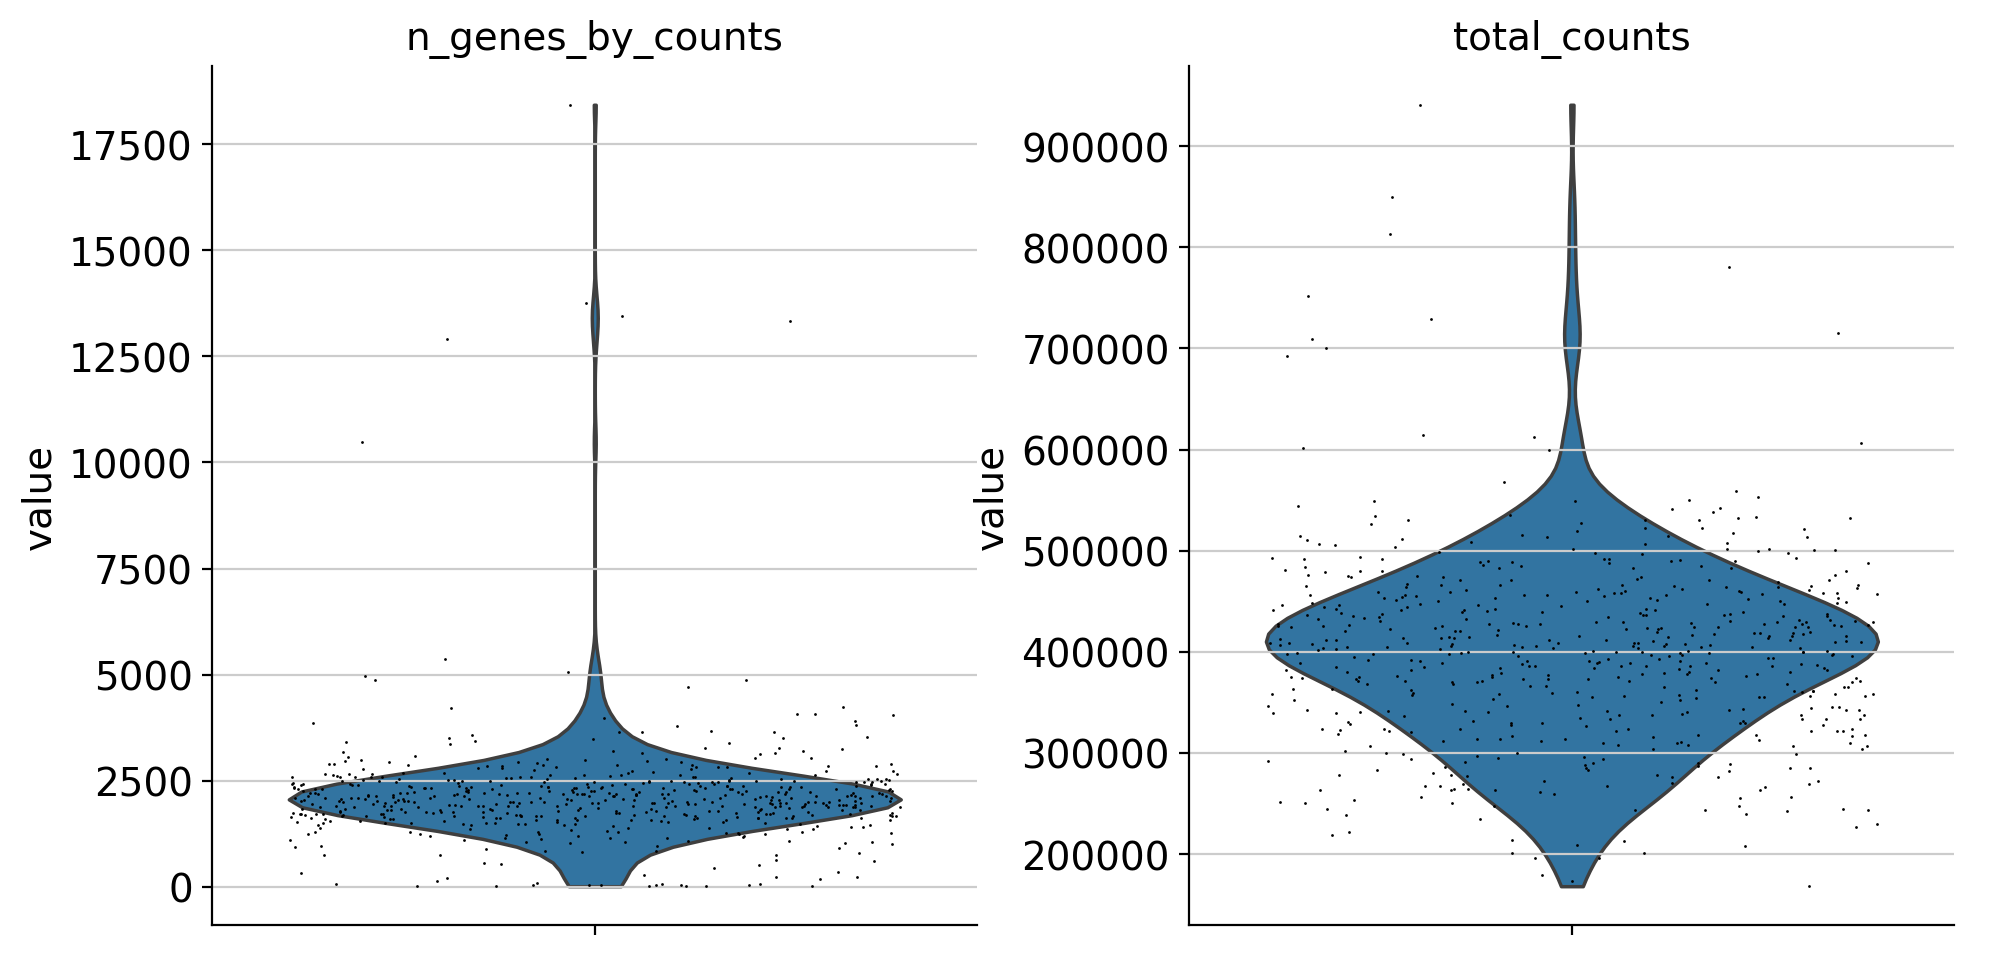

In [122]:
# n_genes_by_counts is number of genes with expression counts >=1
# total counts is the total number of counts for a cell or sum of counts for a gene (if we specify gene)
sc.pl.violin(
    adata_103334_0w,
    ["n_genes_by_counts", "total_counts"],
    jitter=0.4,
    multi_panel=True,
)

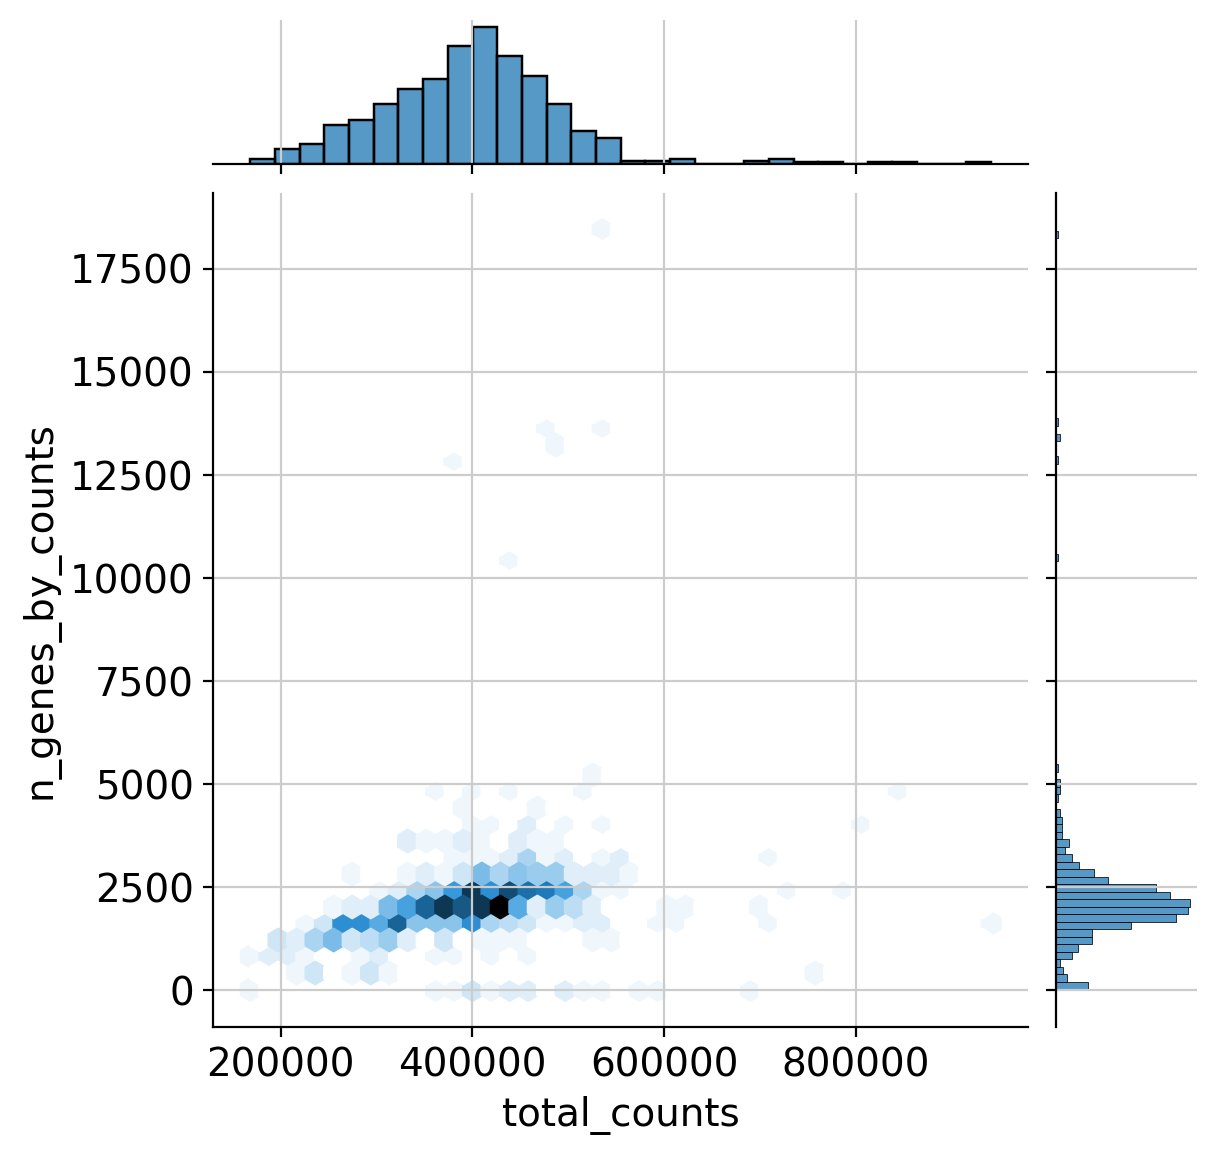

In [123]:
sns.jointplot(
    data=adata_103334_0w.obs,
    x="total_counts",
    y="n_genes_by_counts",
    kind="hex",
)

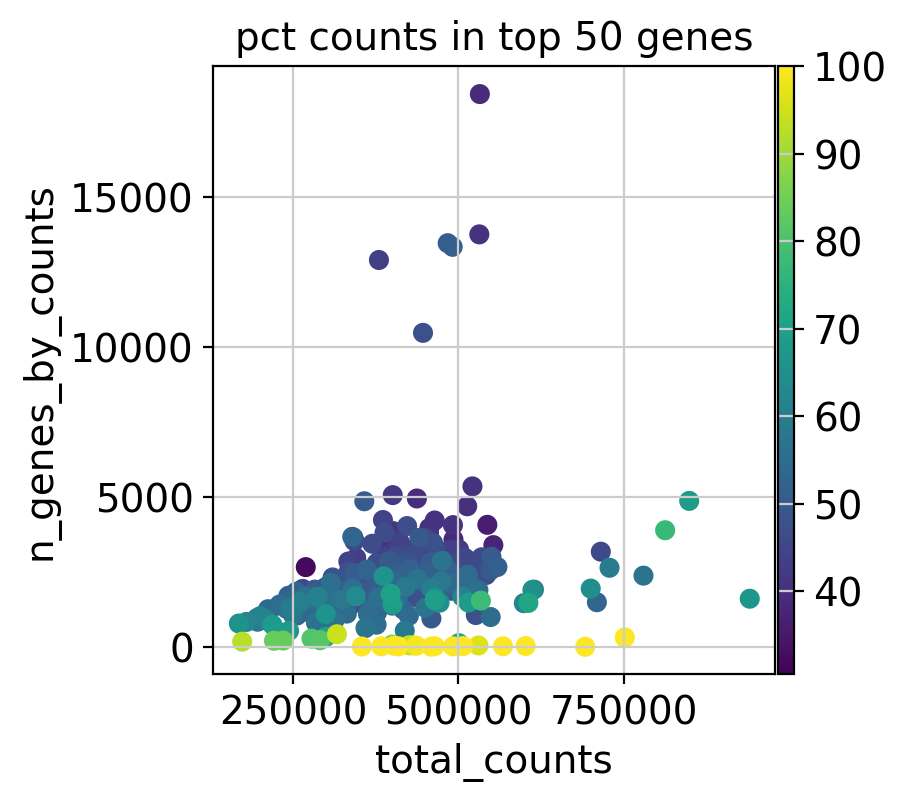

In [134]:
# pct_counts_in_top_50_genes is cumulative percentage of counts from the top 50 most expressed genes
sc.pl.scatter(adata_103334_0w, "total_counts", "n_genes_by_counts", color="pct_counts_in_top_50_genes")

### Identifying potential cell duplicates and normalizing data to median total counts and then log transform

In [ ]:
# Identifying doublets is crucial as they can lead to misclassifications or distortions in downstream analysis steps.
sc.pp.scrublet(adata, batch_key="sample")
# Saving count data
adata.layers["counts"] = adata.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

### Identify highly variable genes in observations pre-PCA check

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata_103334_0w)

### PCA + variance ratio plot + plot by PCAs and color by cell counts of top expressed genes

In [142]:
sc.tl.pca(adata_103334_0w)

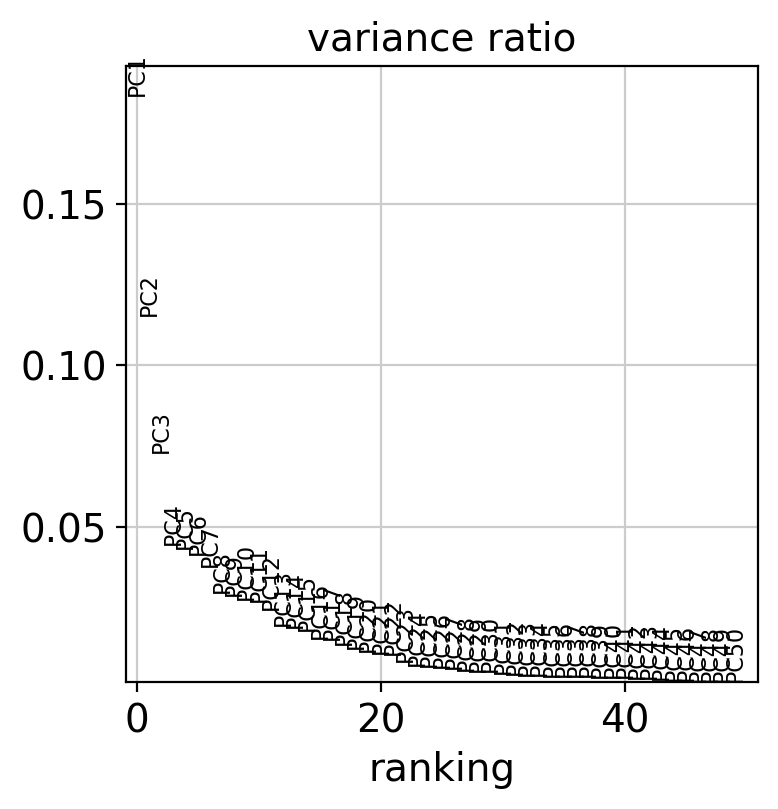

In [174]:
sc.pl.pca_variance_ratio(adata_103334_0w, n_pcs=50)

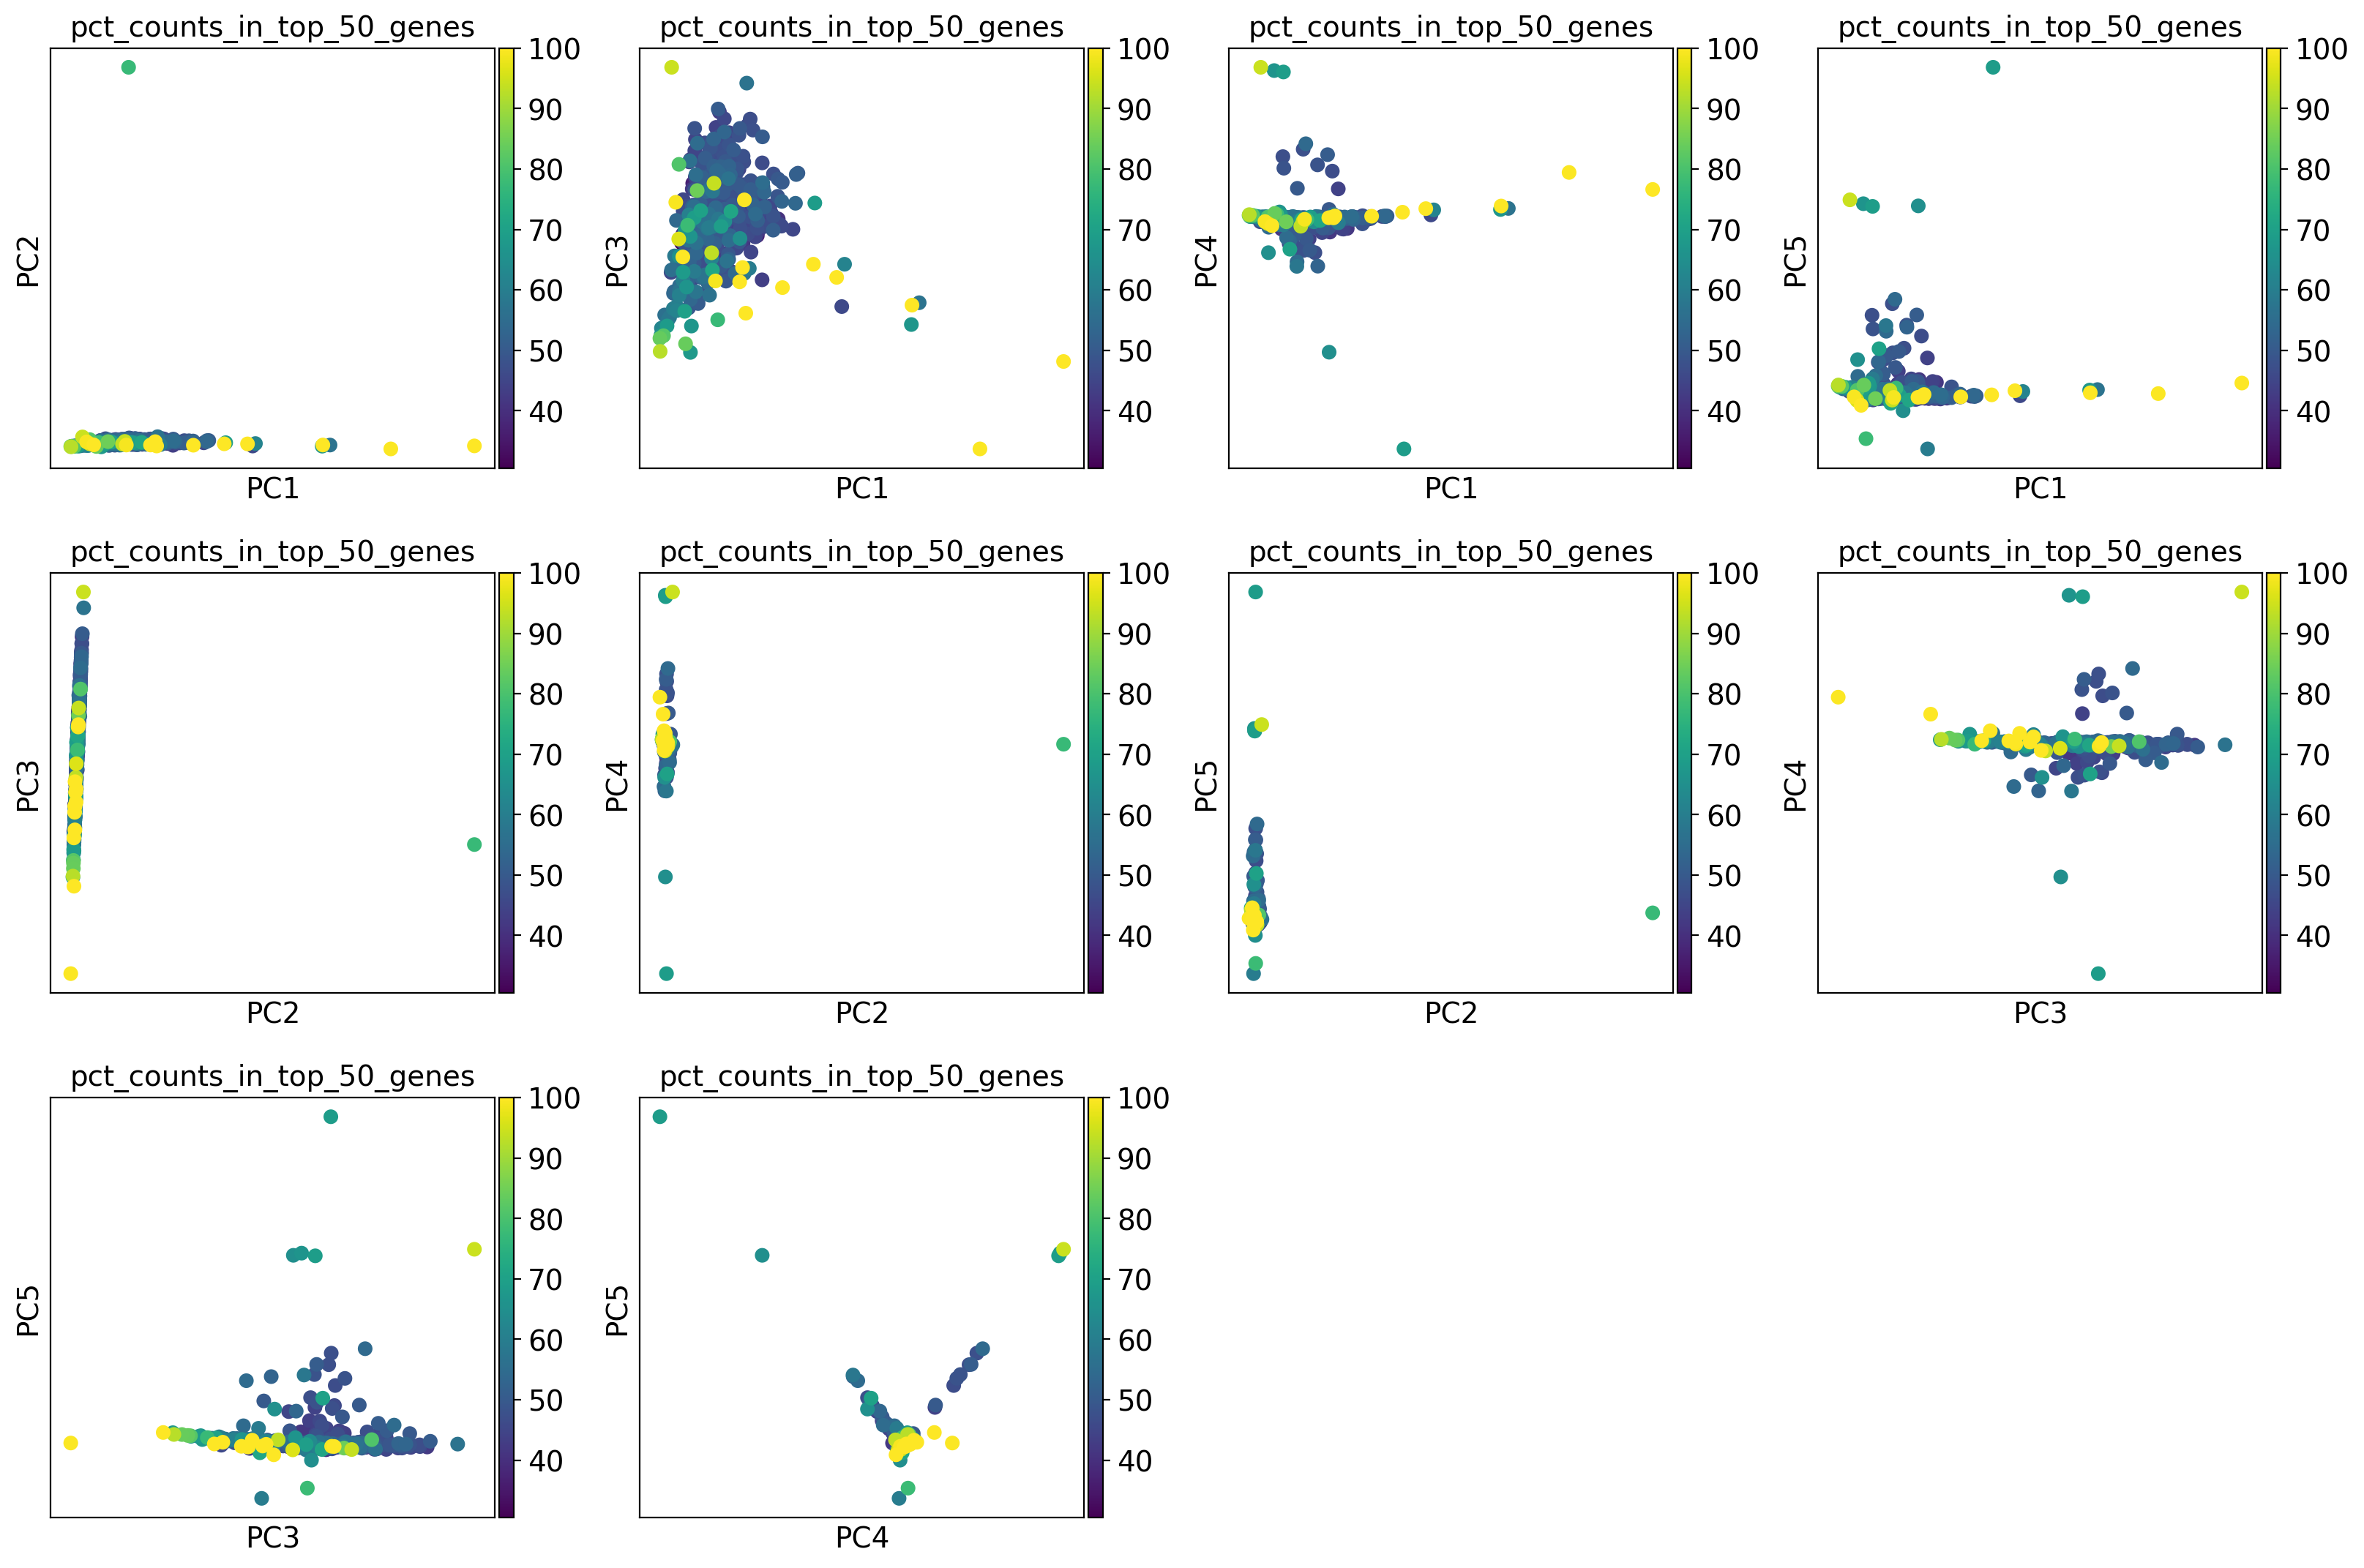

In [179]:
sc.pl.pca(
    adata_103334_0w,
    color="pct_counts_in_top_50_genes",
    dimensions=[(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)],
)

### Obtain neighbors in graph which Leiden clustering uses to cluster

In [146]:
sc.pp.neighbors(adata_103334_0w)

### Use UMAP dimensionality reduction and color by total gene expression count for that cell

In [147]:
sc.tl.umap(adata_103334_0w)

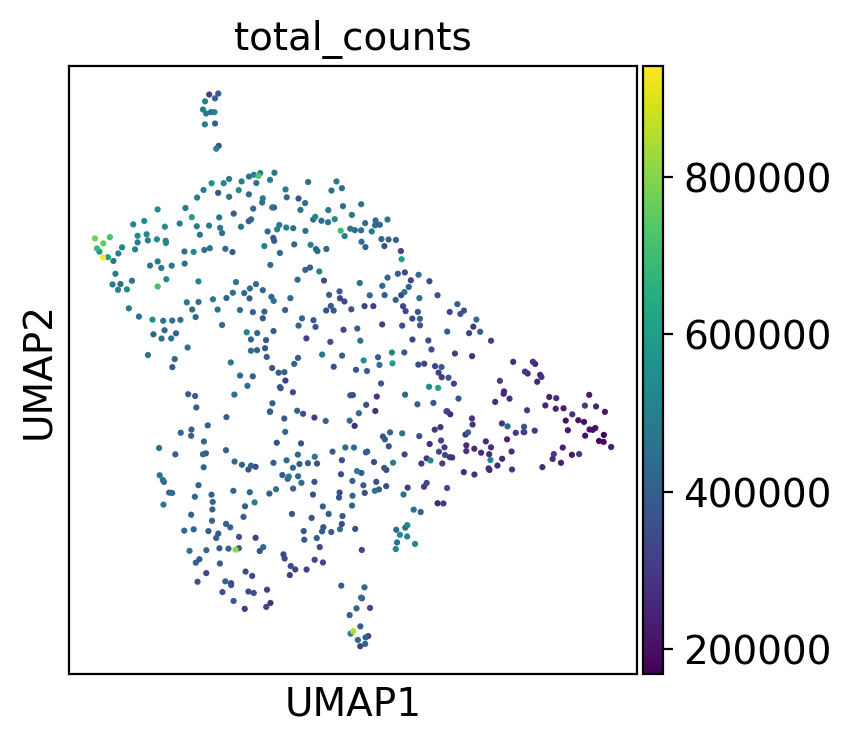

In [162]:
sc.pl.umap(
    adata_103334_0w,
    color="total_counts",
    size=20,
)

### Leiden clustering and UMAP on cells which directly clusters neighborhood graph of cells which we obtained using PCA

In [165]:
# Note that Leiden clustering directly clusters the neighborhood graph of cells, which we already computed in the previous section using the PCA results.
sc.tl.leiden(adata_103334_0w, flavor="igraph", n_iterations=2)

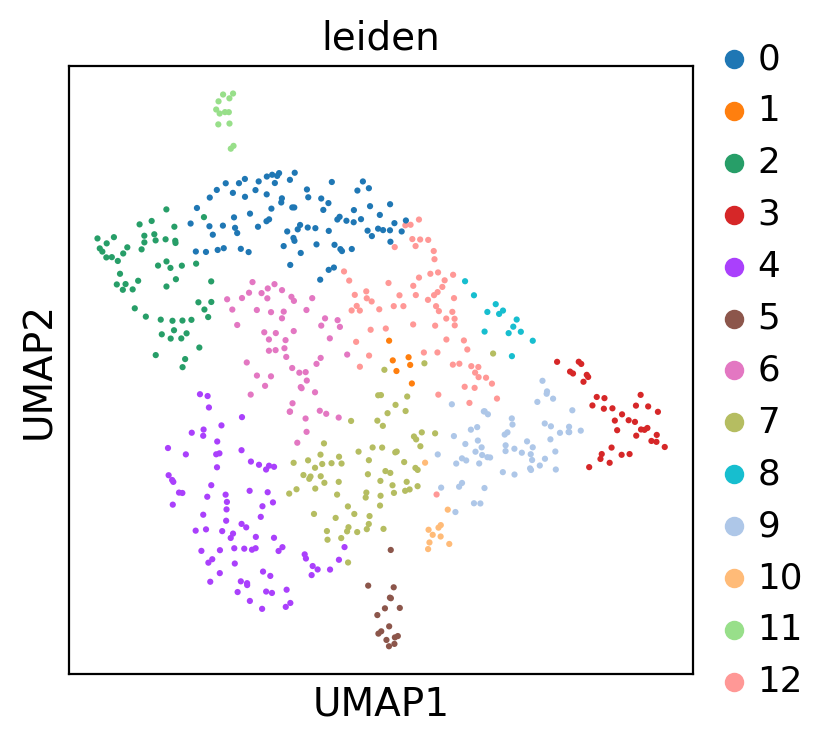

In [170]:
sc.pl.umap(adata_103334_0w, color=["leiden"], size=20)

### UMAP cluster by predicted doublect and doublet score, other QC metrics to perform quality control

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

### Vary resolution parameter in Leiden clustering to identify strong cell type clusters versus sub clusters versus over clustering

In [172]:
# Commonly and classically, cell type annotation uses those marker genes subsequent to the grouping of the cells into clusters. So, let’s generate a set of clustering solutions which we can then use to annotate our cell types. Here, we will use the Leiden clustering algorithm which will extract cell communities from our nearest neighbours graph.
# Notably, the number of clusters that we define is largely arbitrary, and so is the resolution parameter that we use to control for it. As such, the number of clusters is ultimately bound to the stable and biologically-meaningful groups that we can ultimately distringuish, typically done by experts in the corresponding field or by using expert-curated prior knowledge in the form of markers.
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(adata_103334_0w, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

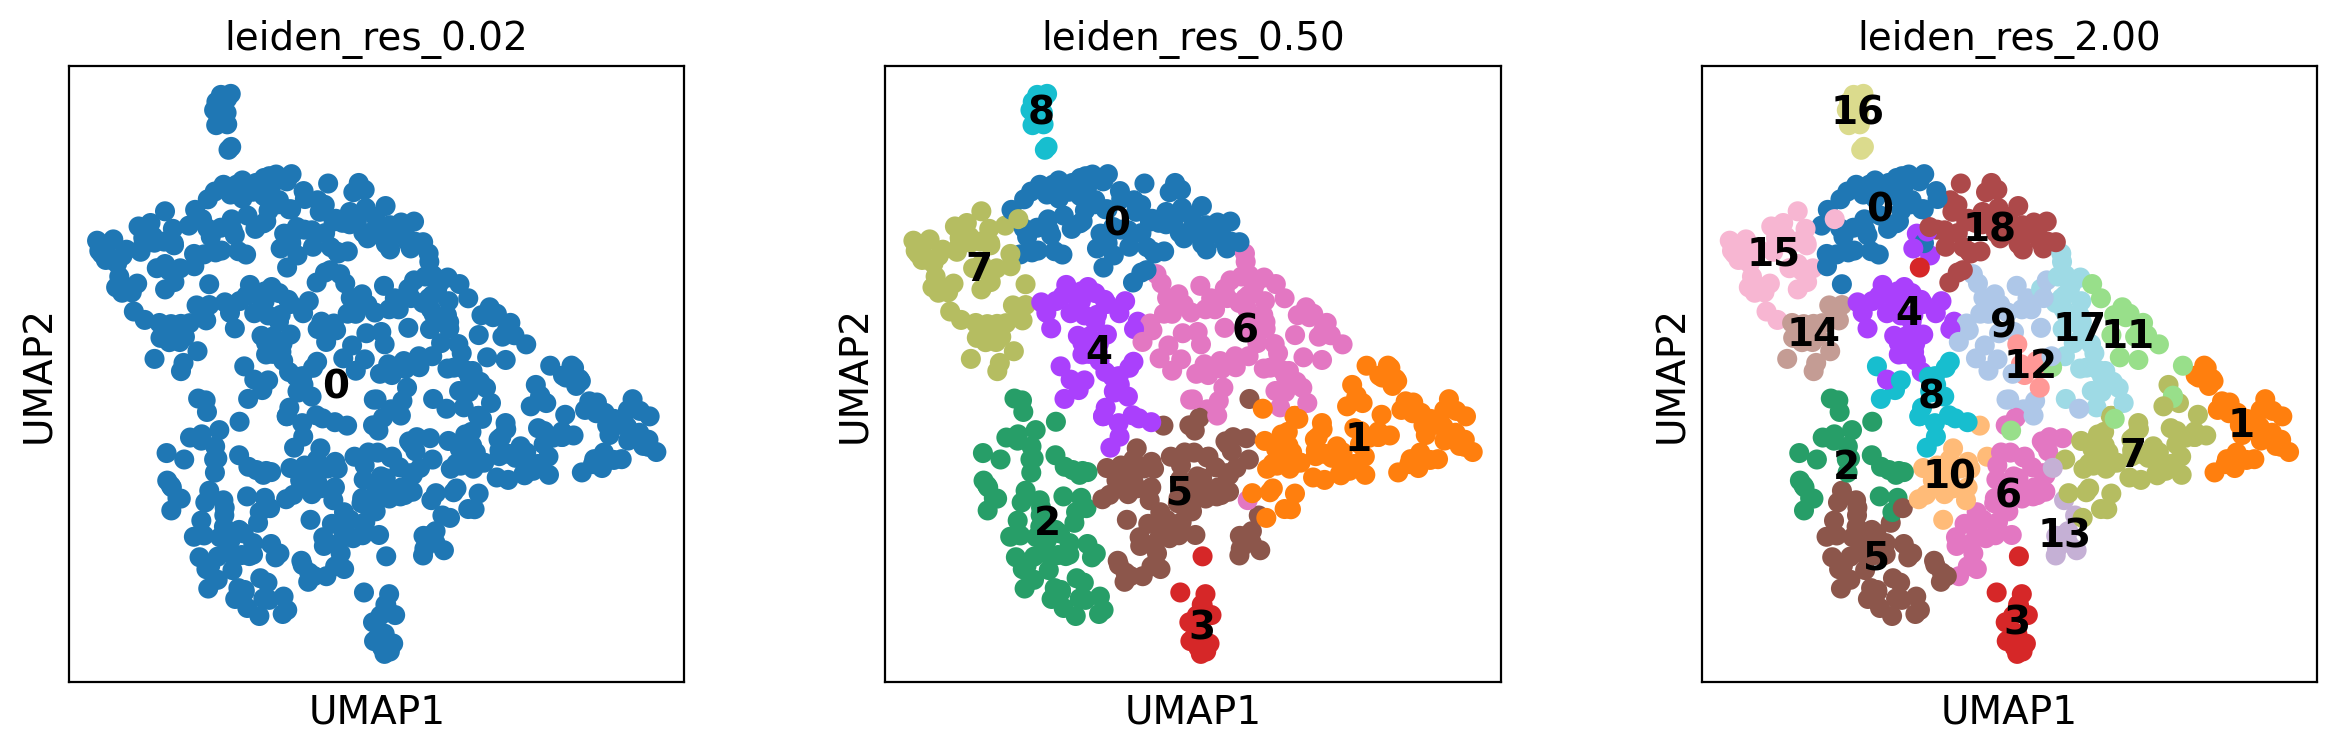

In [173]:
sc.pl.umap(
    adata_103334_0w,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

### Dotplot of marker genes to identify cell types and subtypes using different Leiden resolution params, understand which strongly expressed genes in which clusters have the highest cell count, fraction of cells in group, mean expression

In [ ]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "Erythroid",
        "3": "B Cells",
    }
)
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.50", standard_scale="var")
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5)

### Differentially expressed genes can be extracted in a convenient format with

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

### UMAP clustering of ranked gene group expressions and leiden clustering with resolution 0.5

In [ ]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)